# Pronóstico del número de ocupados en las 13 ciudades principales

Este cuaderno compara regresiones lineales con tendencia y estacionalidad, promedios móviles y configuraciones de suavización exponencial para pronosticar la serie mensual `Ocupados`, expresada en **miles de personas**. La selección se basa en validación cronológica por bloques sobre el período de desarrollo, reservando los últimos seis meses como prueba final que se evalúa una sola vez. El modelo ganador se somete a los diagnósticos de residuos vistos en clase y pronostica seis meses con intervalos de predicción del 95 %.

**Importante sobre las fechas:** el archivo `datosEmpleo.xlsx` disponible en este ejercicio termina en junio de 2019. Por ello, el pronóstico de seis meses generado aquí corresponde a **julio-diciembre de 2019**.

## 1. Paquetes y carga de datos

Se carga la hoja `Hoja1`, se usa `mes` como índice mensual y se valida que las fechas sean únicas y que `Ocupados` no tenga datos faltantes. La columna `Ocupados` se convierte a número y se redondea a tres decimales al cargarla, para ajustarse a la precisión del Excel. No se imputan valores faltantes de forma silenciosa.

In [78]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import shapiro, jarque_bera, norm
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, het_arch
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning, EstimationWarning, ConvergenceWarning
from statsmodels.tsa.arima.model import ARIMA

plt.style.use("seaborn-v0_8-whitegrid")

# Parámetros del ejercicio
HORIZON = 6  # periodo de pronóstico en meses
SEASONAL_PERIODS = 12  # periodo estacional en meses


In [79]:
import os
from pathlib import Path

# Prioridad: 1) variable de entorno DATOS_EMPLEO_PATH, 2) junto al cuaderno, 3) carpeta data/
possible_paths = [
    Path(os.environ["DATOS_EMPLEO_PATH"]) if os.environ.get("DATOS_EMPLEO_PATH") else None,
    Path("datosEmpleo.xlsx"),
    Path("data") / "datosEmpleo.xlsx",
    Path("..") / "datosEmpleo.xlsx",
]
possible_paths = [path for path in possible_paths if path is not None]
data_path = next((path for path in possible_paths if path.is_file()), None)
if data_path is None:
    searched = "\n".join(f"- {path.resolve()}" for path in possible_paths)
    raise FileNotFoundError(
        "No se encontró datosEmpleo.xlsx. Colócalo junto al cuaderno (o en una carpeta "
        "data/), o define la variable de entorno DATOS_EMPLEO_PATH con la ruta completa. "
        f"Rutas revisadas:\n{searched}"
    )

data = pd.read_excel(data_path, sheet_name="Hoja1", parse_dates=["mes"])
required_columns = {"mes", "Ocupados"}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas en el Excel: {sorted(missing_columns)}")

data = data[["mes", "Ocupados"]].copy()
data["Ocupados"] = pd.to_numeric(data["Ocupados"], errors="raise").round(3)
data = data.sort_values("mes").set_index("mes")
if data.index.has_duplicates:
    raise ValueError("La columna mes contiene fechas duplicadas; revísalas antes del análisis.")

# Normaliza las fechas al inicio de cada mes y establece frecuencia mensual explícita.
data.index = data.index.to_period("M").to_timestamp()
data = data.asfreq("MS")
print(f"Archivo: {data_path}")
print(f"Observaciones: {len(data)} | período: {data.index.min():%Y-%m} a {data.index.max():%Y-%m}")
display(data.head())
display(data.tail())


Archivo: datosEmpleo.xlsx
Observaciones: 222 | período: 2001-01 a 2019-06


,Ocupados
mes,
2001-01-01,6923.604
2001-02-01,7037.746
2001-03-01,6945.973
2001-04-01,6973.079
2001-05-01,6994.462


,Ocupados
mes,
2019-02-01,10557.917
2019-03-01,10760.776
2019-04-01,10632.028
2019-05-01,10813.000
2019-06-01,10848.000


## 2. Exploración básica

Se revisan estructura, faltantes, valores descriptivos y trayectoria temporal. La unidad de la variable se conserva como miles de personas.

Dimensiones: (222, 1)
Tipos de datos:
 Ocupados    float64
dtype: object
Valores faltantes:
 Ocupados    0
dtype: int64


,Ocupados (miles)
count,222.000000
mean,9160.852009
std,1295.492800
min,6923.604000
25%,7971.103000
50%,9139.064500
75%,10458.510250
max,11037.199000


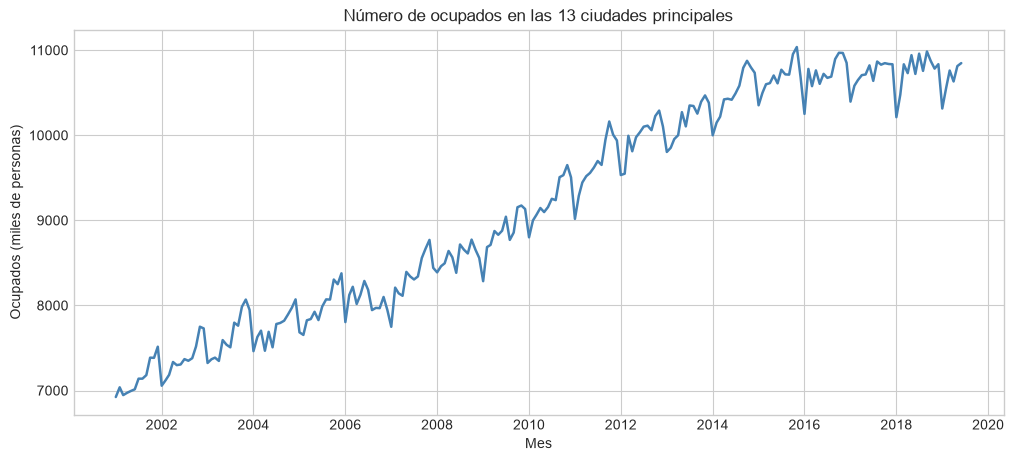

In [80]:
print("Dimensiones:", data.shape)
print("Tipos de datos:\n", data.dtypes)
print("Valores faltantes:\n", data.isna().sum())
display(data["Ocupados"].describe().to_frame("Ocupados (miles)"))

if data["Ocupados"].isna().any():
    missing_months = data.index[data["Ocupados"].isna()].strftime("%Y-%m").tolist()
    raise ValueError(
        "Hay meses sin dato de Ocupados después de establecer la frecuencia mensual: "
        f"{missing_months}. Completa o corrige la fuente antes de modelar."
    )
if len(data) < 48:
    raise ValueError("Se requieren al menos 48 meses para separar seis meses de prueba y ajustar modelos estacionales anuales.")

y = data["Ocupados"].astype(float)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y, color="steelblue", linewidth=1.8)
ax.set(title="Número de ocupados en las 13 ciudades principales", xlabel="Mes", ylabel="Ocupados (miles de personas)")
plt.show()

## 3. Estacionariedad de la serie

Antes de comparar pronósticos se examina la estacionariedad débil en los datos de desarrollo (sin los seis meses reservados para prueba): media y desviación estándar móviles de 12 meses, y dos pruebas complementarias — ADF (H₀: raíz unitaria) y KPSS (H₀: estacionariedad). En nivel se incluyen constante y tendencia en ambas pruebas; en primera diferencia, solo constante. Las pruebas aportan evidencia, pero no demuestran por sí solas que la serie sea estacionaria. Nota de reporte: los p-valores de KPSS son cotas de la tabla de referencia, por lo que se leen como ≤ 0.01 o ≥ 0.10 cuando el estadístico cae por fuera del rango tabulado.


,Serie,ADF p-valor (H0: raíz unitaria),KPSS p-valor (H0: estacionaria)
0,Serie en nivel,0.9286,0.01
1,Primera diferencia,0.0098,0.10


Lectura conjunta de estacionariedad:
- En nivel: ADF p = 0.9286; KPSS p ≤ 0.01 (rechaza estacionariedad).
- En primera diferencia: ADF p = 0.0098; KPSS p ≥ 0.10 (no rechaza estacionariedad).
→ La serie no es estacionaria en nivel pero sí en primera diferencia: se comporta como integrada de orden 1,
  lo que favorece a los modelos que adaptan el nivel localmente (promedios móviles, ETS) frente a tendencias globales fijas.


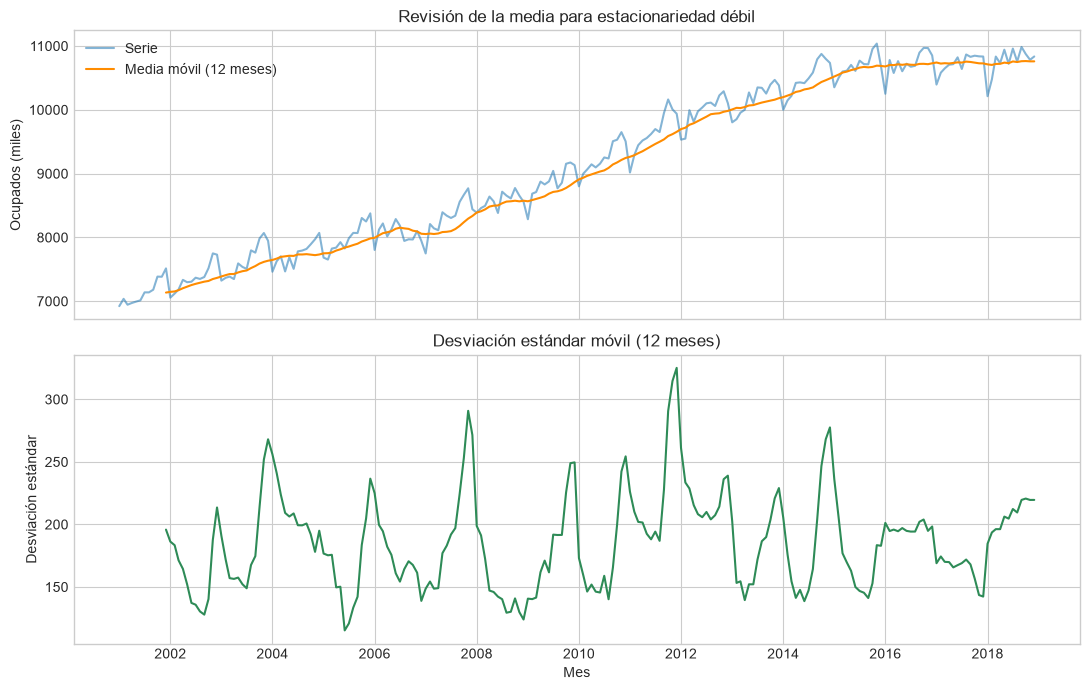

In [81]:
# Datos de desarrollo: toda la serie menos los seis meses reservados como prueba final.
development_series = y.iloc[:-HORIZON].astype(float)
stationarity_cases = [
    ("Serie en nivel", development_series, "ct", "ct"),
    ("Primera diferencia", development_series.diff().dropna(), "c", "c"),
]
stationarity_rows = []
for label, series, adf_regression, kpss_regression in stationarity_cases:
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=InterpolationWarning)
        adf_result = adfuller(
            series, regression=adf_regression, autolag="AIC", result_object=True
        )
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=InterpolationWarning)
        warnings.filterwarnings("ignore", category=FutureWarning)
        kpss_result = kpss(
            series, regression=kpss_regression, nlags="auto"
        )
    stationarity_rows.append({
        "Serie": label,
        "ADF p-valor (H0: raíz unitaria)": adf_result.pvalue,
        "KPSS p-valor (H0: estacionaria)": kpss_result[1],
    })
stationarity_results = pd.DataFrame(stationarity_rows)
display(stationarity_results.round(4))

# Lectura conjunta de las dos pruebas
adf_nivel = stationarity_results.loc[0, "ADF p-valor (H0: raíz unitaria)"]
kpss_nivel = stationarity_results.loc[0, "KPSS p-valor (H0: estacionaria)"]
adf_dif = stationarity_results.loc[1, "ADF p-valor (H0: raíz unitaria)"]
kpss_dif = stationarity_results.loc[1, "KPSS p-valor (H0: estacionaria)"]

def kpss_texto(p):
    if p <= 0.01:
        return "p ≤ 0.01 (rechaza estacionariedad)"
    if p >= 0.10:
        return "p ≥ 0.10 (no rechaza estacionariedad)"
    return f"p = {p:.4f}"

print("Lectura conjunta de estacionariedad:")
print(f"- En nivel: ADF p = {adf_nivel:.4f}; KPSS {kpss_texto(kpss_nivel)}.")
print(f"- En primera diferencia: ADF p = {adf_dif:.4f}; KPSS {kpss_texto(kpss_dif)}.")
if adf_nivel > 0.05 and kpss_nivel <= 0.05 and adf_dif <= 0.05 and kpss_dif > 0.05:
    print("→ La serie no es estacionaria en nivel pero sí en primera diferencia: se comporta como integrada de orden 1,")
    print("  lo que favorece a los modelos que adaptan el nivel localmente (promedios móviles, ETS) frente a tendencias globales fijas.")
else:
    print("→ La evidencia no es concluyente en ambas pruebas; revisar la tabla antes de continuar.")

rolling_mean = development_series.rolling(SEASONAL_PERIODS).mean()
rolling_std = development_series.rolling(SEASONAL_PERIODS).std()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(development_series.index, development_series, alpha=0.55, label="Serie")
axes[0].plot(rolling_mean.index, rolling_mean, color="darkorange", label="Media móvil (12 meses)")
axes[0].set(title="Revisión de la media para estacionariedad débil", ylabel="Ocupados (miles)")
axes[0].legend()
axes[1].plot(rolling_std.index, rolling_std, color="seagreen")
axes[1].set(title="Desviación estándar móvil (12 meses)", xlabel="Mes", ylabel="Desviación estándar")
plt.tight_layout()
plt.show()


## 4. Estrategia de evaluación

Para evitar elegir configuraciones usando el conjunto de prueba, se separan los **últimos seis meses observados** como prueba final, que no participa en el ajuste ni en la selección. Los datos anteriores (desarrollo) se usan para comparar candidatos en seis bloques cronológicos de validación, cada uno de seis meses. En cada bloque, el modelo se ajusta solo con observaciones anteriores al bloque y pronostica sus seis meses siguientes.

Se selecciona la configuración con menor RMSE promedio entre los seis bloques de validación; MAE y sMAPE complementan la comparación, y se reporta la variabilidad del RMSE entre bloques. Solo después de seleccionar el modelo, se evalúa una vez contra los seis meses finales reservados. Los promedios móviles se pronostican recursivamente, incorporando cada estimación a la ventana siguiente. Esta validación temporal repetida es más informativa que escoger y reportar el ganador en el mismo bloque.

In [82]:
if len(y) <= 7 * HORIZON:
    raise ValueError("La serie es demasiado corta para conservar prueba final y seis bloques de validación.")

train_eval = y.iloc[:-HORIZON]
test_eval = y.iloc[-HORIZON:]
validation_origins = list(range(len(train_eval) - 6 * HORIZON, len(train_eval), HORIZON))
validation_folds = [
    (train_eval.iloc[:origin], train_eval.iloc[origin:origin + HORIZON])
    for origin in validation_origins
]

print(f"Horizonte de cada pronóstico: {HORIZON} meses")
print(f"Desarrollo para validación: {train_eval.index[0]:%Y-%m} a {train_eval.index[-1]:%Y-%m} ({len(train_eval)} meses)")
for fold_number, (train_fold, validation_fold) in enumerate(validation_folds, start=1):
    print(f"Validación {fold_number}: entrenamiento hasta {train_fold.index[-1]:%Y-%m}; "
          f"validación {validation_fold.index[0]:%Y-%m} a {validation_fold.index[-1]:%Y-%m}")
print(f"Prueba final reservada: {test_eval.index[0]:%Y-%m} a {test_eval.index[-1]:%Y-%m} ({len(test_eval)} meses)")

Horizonte de cada pronóstico: 6 meses
Desarrollo para validación: 2001-01 a 2018-12 (216 meses)
Validación 1: entrenamiento hasta 2015-12; validación 2016-01 a 2016-06
Validación 2: entrenamiento hasta 2016-06; validación 2016-07 a 2016-12
Validación 3: entrenamiento hasta 2016-12; validación 2017-01 a 2017-06
Validación 4: entrenamiento hasta 2017-06; validación 2017-07 a 2017-12
Validación 5: entrenamiento hasta 2017-12; validación 2018-01 a 2018-06
Validación 6: entrenamiento hasta 2018-06; validación 2018-07 a 2018-12
Prueba final reservada: 2019-01 a 2019-06 (6 meses)


## 5. Modelos candidatos

- **Regresión lineal:** tendencias lineal, cuadrática y cúbica; cada forma se evalúa con y sin estacionalidad mensual. 
- **Promedios móviles:** ventanas de 2 a 12 meses, tanto con pesos iguales como con pesos lineales crecientes para dar mayor peso a los datos recientes.
- **Suavización exponencial mediante ETS:** se comparan configuraciones con y sin tendencia, con estacionalidad aditiva o multiplicativa cuando corresponde. Para configuraciones estacionales se usa un ciclo de 12 meses.
- **ARIMA:** se ajusta una búsqueda limitada de órdenes (p, d, q), con d = 0 o 1, y se selecciona por AIC dentro de cada bloque de entrenamiento. En este cuaderno el ajuste de ARIMA se implementa con `statsmodels`, siguiendo la lógica de `auto_arima`: elegir el orden y evitar usar los datos reservados para validación o prueba.

Para suavizar datos observados, `rolling(window).mean()` calcula el promedio móvil en cada fecha. Para pronosticar una fecha futura, el código usa `shift(1).rolling(...)`: desplaza los datos conocidos para que el promedio quede alineado con el mes que se quiere estimar, sin incluir un valor real de ese mes. En pronósticos de varios meses, cada predicción se agrega al historial y se usa para calcular la siguiente.

En las medias ponderadas se usan pesos 1, 2, ..., ventana, normalizados para sumar uno. Todos los candidatos se comparan en los mismos bloques de validación; los seis meses de prueba final permanecen fuera de la selección.

En las salidas ETS se muestran únicamente los parámetros de suavización: **α (alfa)** ajusta el nivel de la serie y determina cuánto influyen los datos recientes; **β (beta)** ajusta la tendencia; y **γ (gamma)** ajusta el patrón estacional. Un valor más alto da más peso a los cambios recientes y uno más bajo suaviza más. Si un modelo no incluye tendencia o estacionalidad, β o γ aparece como «No aplica».

In [83]:
def moving_average_forecast(train, window, horizon, weighted=False):
    """Pronostica recursivamente; shift().rolling() alinea el promedio pasado con cada mes futuro."""
    history = train.astype(float).copy()
    predictions = []

    for _ in range(horizon):
        next_month = history.index[-1] + pd.DateOffset(months=1)
        # Añade el mes a pronosticar; shift(1) coloca en él solo los valores ya conocidos.
        extended_history = pd.concat([history, pd.Series([np.nan], index=[next_month])])
        shifted = extended_history.shift(1)
        if weighted:
            weights = np.arange(1, window + 1, dtype=float)
            moving_average = shifted.rolling(window=window, min_periods=window).apply(
                lambda values: np.average(values, weights=weights), raw=True
            )
        else:
            moving_average = shifted.rolling(window=window, min_periods=window).mean()
        next_value = float(moving_average.loc[next_month])
        predictions.append(next_value)

        # Incorpora el pronóstico para poder calcular el siguiente mes futuro.
        history.loc[next_month] = next_value

    return np.asarray(predictions)


def linear_regression_forecast(train, horizon, trend_form, include_seasonality):
    train = train.astype(float)
    train_time = np.arange(len(train), dtype=float)

    def design_matrix(index, time_values):
        years = time_values / 12
        if trend_form == "lineal":
            features = pd.DataFrame({"t": years}, index=index)
        elif trend_form == "cuadrática":
            features = pd.DataFrame({"t": years, "t2": years ** 2}, index=index)
        elif trend_form == "cúbica":
            features = pd.DataFrame(
                {"t": years, "t2": years ** 2, "t3": years ** 3}, index=index
            )
        else:
            raise ValueError(f"Forma de tendencia desconocida: {trend_form}")
        if include_seasonality:
            for month in range(2, 13):
                features[f"mes_{month}"] = (index.month == month).astype(float)
        return sm.add_constant(features, has_constant="add")

    x_train = design_matrix(train.index, train_time)
    fitted = sm.OLS(train, x_train).fit()
    future_index = pd.date_range(
        start=train.index[-1], periods=horizon + 1, freq="MS"
    )[1:]
    future_time = np.arange(len(train), len(train) + horizon, dtype=float)
    predictions = fitted.predict(design_matrix(future_index, future_time))
    return fitted, predictions


def fit_arima_model(train):
    """Busca una configuracion ARIMA(p,d,q) por AIC y devuelve ajuste y orden."""
    train = train.astype(float)
    best_fit = None
    best_order = None
    best_aic = np.inf #infinito

    for d in (0, 1):
        for p in range(4):
            for q in range(4):
                order = (p, d, q)
                try:
                    trend = "n" if d > 0 else "c"
                    with warnings.catch_warnings():
                        warnings.filterwarnings("ignore", category=ConvergenceWarning)
                        warnings.filterwarnings("ignore", category=EstimationWarning)
                        candidate = ARIMA(
                            train, order=order, trend=trend
                        ).fit(method_kwargs={"maxiter": 500})

                    mle_retvals = getattr(candidate, "mle_retvals", {})
                    converged = bool(mle_retvals.get("converged", True))
                    ar_roots = np.asarray(getattr(candidate, "arroots", []), dtype=complex)
                    ma_roots = np.asarray(getattr(candidate, "maroots", []), dtype=complex)
                    stationary = len(ar_roots) == 0 or np.all(np.abs(ar_roots) > 1)
                    invertible = len(ma_roots) == 0 or np.all(np.abs(ma_roots) > 1)

                    if (converged and stationary and invertible
                            and np.isfinite(candidate.aic)
                            and candidate.aic < best_aic):
                        best_fit = candidate
                        best_order = order
                        best_aic = float(candidate.aic)
                except (ValueError, np.linalg.LinAlgError):
                    continue

    if best_fit is None:
        raise ValueError("No fue posible ajustar ninguna configuracion ARIMA candidata.")
    return best_fit, best_order


def fit_ets_model(model_name, train):
    """Ajusta una configuración ETS y devuelve el objeto de resultados completo (para pronóstico y diagnóstico)."""
    if model_name == "ETS - error aditivo, sin tendencia":
        return ETSModel(train, error="add").fit(disp=False)
    if model_name == "ETS - error aditivo, estacionalidad aditiva":
        return ETSModel(
            train, error="add", seasonal="add",
            seasonal_periods=SEASONAL_PERIODS,
        ).fit(disp=False)
    if model_name == "ETS - error y tendencia multiplicativos":
        if (train <= 0).any():
            raise ValueError("El ETS multiplicativo requiere valores estrictamente positivos.")
        return ETSModel(train, error="mul", trend="mul").fit(disp=False)
    if model_name == "ETS - error aditivo, tendencia y estacionalidad aditivas":
        return ETSModel(
            train, error="add", trend="add", seasonal="add",
            seasonal_periods=SEASONAL_PERIODS,
        ).fit(disp=False)
    if model_name == "ETS - error aditivo, estacionalidad multiplicativa":
        if (train <= 0).any():
            raise ValueError("La estacionalidad multiplicativa requiere valores estrictamente positivos.")
        return ETSModel(
            train, error="add", seasonal="mul",
            seasonal_periods=SEASONAL_PERIODS,
        ).fit(disp=False)
    raise ValueError(f"Configuración de modelo desconocida: {model_name}")


def forecast_model(model_name, train, horizon, verbose=False):
    """Ajusta una configuración candidata usando solo `train` y devuelve el horizonte solicitado."""
    if model_name.startswith("Promedio móvil"):
        weighted = "ponderado" in model_name
        window = int(model_name.rsplit(" ", 1)[-1])
        return moving_average_forecast(train, window, horizon, weighted)

    if model_name.startswith("Regresión "):
        include_seasonality = "y estacionalidad" in model_name
        if model_name.startswith("Regresión lineal"):
            trend_form = "lineal"
        elif model_name.startswith("Regresión cúbica"):
            trend_form = "cúbica"
        elif model_name.startswith("Regresión cuadrática"):
            trend_form = "cuadrática"
        else:
            raise ValueError(f"Configuración de regresión desconocida: {model_name}")
        _, predictions = linear_regression_forecast(
            train, horizon, trend_form, include_seasonality
        )
        return np.asarray(predictions, dtype=float)

    if model_name == "ARIMA (búsqueda por AIC)":
        fitted, order = fit_arima_model(train)
        predictions = np.asarray(fitted.forecast(horizon), dtype=float)
        if verbose:
            print(f"Modelo ARIMA ajustado. Orden seleccionado por AIC: ARIMA{order}")
            print(f"Pronóstico de ARIMA{order} para {horizon} meses: {predictions}")
        return predictions

    fitted = fit_ets_model(model_name, train)
    alpha = getattr(fitted, "alpha", None)
    beta = getattr(fitted, "beta", None)
    gamma = getattr(fitted, "gamma", None)
    format_parameter = lambda value: f"{value:.3f}" if value is not None else "No aplica"
    predictions = np.asarray(fitted.forecast(horizon), dtype=float)
    if verbose:
        print(
        f"Modelo {model_name} ajustado. Parámetros de suavización: "
        f"α (alfa)={format_parameter(alpha)}, "
        f"β (beta)={format_parameter(beta)}, "
        f"γ (gamma)={format_parameter(gamma)}"
        )
        print(f"Pronóstico de {model_name} para {horizon} meses: {predictions}")
    return predictions


model_names = [
    "Regresión lineal - tendencia",
    "Regresión lineal - tendencia y estacionalidad",
    "Regresión cuadrática - tendencia",
    "Regresión cuadrática - tendencia y estacionalidad",
    "Regresión cúbica - tendencia",
    "Regresión cúbica - tendencia y estacionalidad",
]
model_names.extend(f"Promedio móvil {window}" for window in range(2, 13))
model_names.extend(f"Promedio móvil ponderado {window}" for window in range(2, 13))
model_names.extend([
    "ETS - error aditivo, sin tendencia",
    "ETS - error aditivo, estacionalidad aditiva",
    "ETS - error y tendencia multiplicativos",
    "ETS - error aditivo, tendencia y estacionalidad aditivas",
    "ETS - error aditivo, estacionalidad multiplicativa",
])
model_names.append("ARIMA (búsqueda por AIC)")

if (y <= 0).any():
    model_names.remove("ETS - error y tendencia multiplicativos")
    model_names.remove("ETS - error aditivo, estacionalidad multiplicativa")


## 6. Evaluación y comparación

La configuración se elige con el menor RMSE promedio en los seis bloques de validación. Para ARIMA, el orden (p, d, q) se vuelve a seleccionar por AIC dentro de cada bloque de entrenamiento, sin usar observaciones futuras. La prueba final no interviene en esta selección y se evalúa únicamente después de fijar al ganador. MAE, sMAPE y la desviación estándar del RMSE entre bloques complementan la comparación. La tabla compara todos los candidatos en igualdad de condiciones; la comparación entre regresiones con y sin estacionalidad se lee directamente en el ranking.

In [84]:
validation_rows = []
for fold_number, (train_fold, validation_fold) in enumerate(validation_folds, start=1):
    actual_values = validation_fold.to_numpy(dtype=float)
    for name in model_names:
        predicted_values = forecast_model(name, train_fold, HORIZON)
        if len(predicted_values) != HORIZON or not np.isfinite(predicted_values).all():
            raise ValueError(f"Pronóstico inválido o desalineado para {name}, bloque {fold_number}.")
        denominator = np.abs(actual_values) + np.abs(predicted_values)
        smape = np.mean(2 * np.abs(actual_values - predicted_values) / denominator) * 100
        validation_rows.append({
            "Bloque": fold_number,
            "Modelo": name,
            "MAE (miles)": mean_absolute_error(actual_values, predicted_values),
            "RMSE (miles)": np.sqrt(mean_squared_error(actual_values, predicted_values)),
            "sMAPE (%)": smape,
        })

validation_results = pd.DataFrame(validation_rows)
validation_scores = (
    validation_results.groupby("Modelo")
    .agg({
        "MAE (miles)": "mean",
        "RMSE (miles)": ["mean", "std"],
        "sMAPE (%)": "mean",
    })
)
validation_scores.columns = ["MAE promedio (miles)", "RMSE promedio (miles)", "Desv. estándar RMSE", "sMAPE promedio (%)"]
validation_scores = validation_scores.sort_values("RMSE promedio (miles)").reset_index()
display(validation_scores.round(3))
best_model_name = validation_scores.loc[0, "Modelo"]
runner_up_name = validation_scores.loc[1, "Modelo"]
rmse_gap = validation_scores.loc[1, "RMSE promedio (miles)"] - validation_scores.loc[0, "RMSE promedio (miles)"]
print(f"Configuración seleccionada por RMSE promedio de validación: {best_model_name}")
print(f"Segundo lugar: {runner_up_name} (a {rmse_gap:.3f} miles de RMSE promedio).")

# El conjunto final de prueba se usa una sola vez, después de elegir la configuración.
test_actual = test_eval.to_numpy(dtype=float)
test_index = test_eval.index
test_prediction = forecast_model(best_model_name, train_eval, HORIZON)
test_denominator = np.abs(test_actual) + np.abs(test_prediction)
holdout_scores = pd.DataFrame([{
    "Modelo seleccionado": best_model_name,
    "MAE prueba (miles)": mean_absolute_error(test_actual, test_prediction),
    "RMSE prueba (miles)": np.sqrt(mean_squared_error(test_actual, test_prediction)),
    "sMAPE prueba (%)": np.mean(2 * np.abs(test_actual - test_prediction) / test_denominator) * 100,
}])
display(holdout_scores.round(3))
val_rmse_best = validation_scores.loc[0, "RMSE promedio (miles)"]
test_rmse_best = holdout_scores.loc[0, "RMSE prueba (miles)"]
print(f"RMSE del modelo seleccionado: {val_rmse_best:.3f} miles en validación vs. {test_rmse_best:.3f} miles en prueba final.")
if test_rmse_best <= val_rmse_best:
    print("El desempeño en prueba es igual o mejor que en validación: la selección no quedó sobreajustada al desarrollo.")
else:
    print("El desempeño en prueba es peor que en validación; conviene revisar la estabilidad del modelo seleccionado.")
predictions_by_model = {best_model_name: test_prediction}

,Modelo,MAE promedio (miles),RMSE promedio (miles),Desv. estándar RMSE,sMAPE promedio (%)
0,"ETS - error aditivo, estacionalidad aditiva",109.345,125.809,36.137,1.019
1,"ETS - error aditivo, estacionalidad multiplica...",107.241,130.274,52.187,0.996
2,"ETS - error aditivo, tendencia y estacionalida...",139.121,155.708,36.405,1.289
3,Promedio móvil 12,147.348,181.585,46.608,1.377
4,ARIMA (búsqueda por AIC),150.012,190.332,87.660,1.401
5,Promedio móvil 11,157.141,195.075,47.066,1.469
6,Promedio móvil ponderado 2,155.032,201.473,90.331,1.447
7,"ETS - error aditivo, sin tendencia",157.678,202.392,86.411,1.472
8,Promedio móvil 10,166.321,204.777,47.347,1.554
9,Promedio móvil ponderado 12,163.849,204.801,55.146,1.530


Configuración seleccionada por RMSE promedio de validación: ETS - error aditivo, estacionalidad aditiva
Segundo lugar: ETS - error aditivo, estacionalidad multiplicativa (a 4.465 miles de RMSE promedio).


,Modelo seleccionado,MAE prueba (miles),RMSE prueba (miles),sMAPE prueba (%)
0,"ETS - error aditivo, estacionalidad aditiva",73.783,84.004,0.693


RMSE del modelo seleccionado: 125.809 miles en validación vs. 84.004 miles en prueba final.
El desempeño en prueba es igual o mejor que en validación: la selección no quedó sobreajustada al desarrollo.


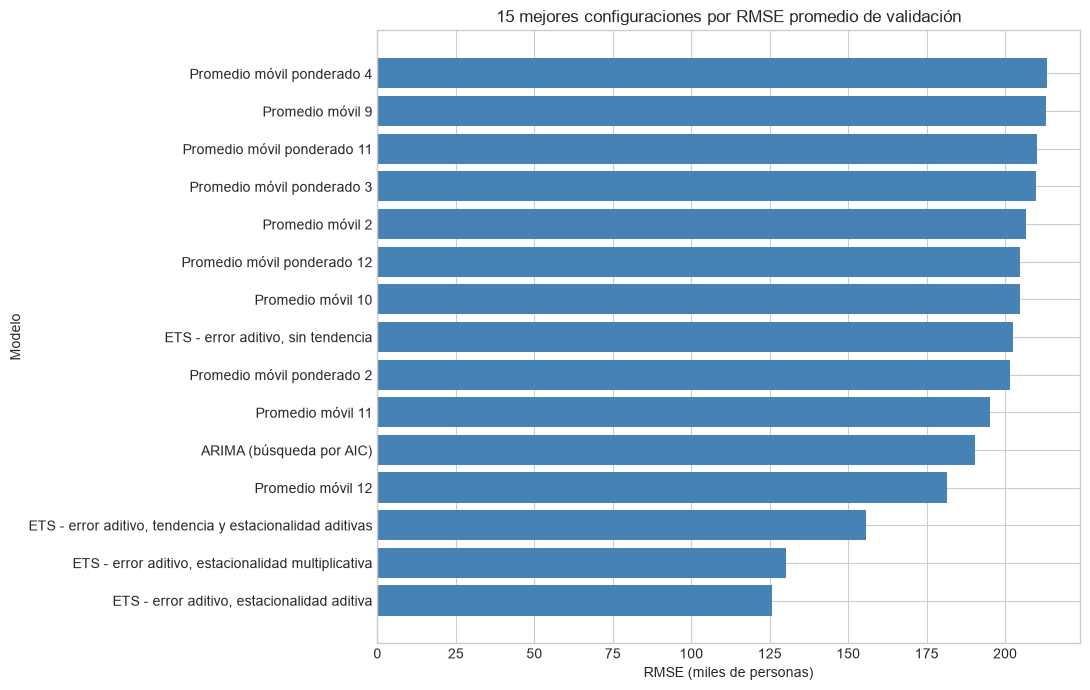

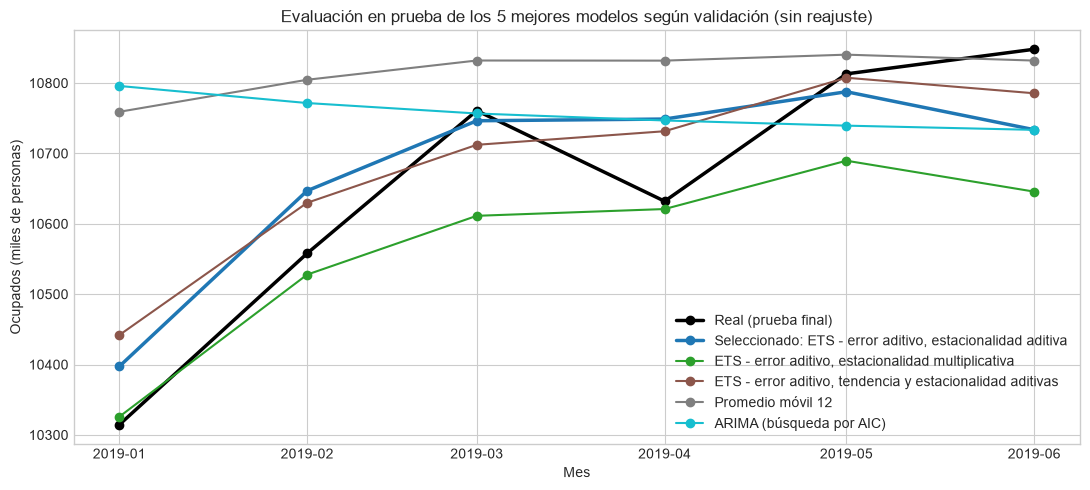

In [85]:
top_models = validation_scores.head(15).sort_values("RMSE promedio (miles)", ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_models["Modelo"], top_models["RMSE promedio (miles)"], color="steelblue")
ax.set(title="15 mejores configuraciones por RMSE promedio de validación", xlabel="RMSE (miles de personas)", ylabel="Modelo")
plt.tight_layout()
plt.show()

top_5_models = validation_scores.head(5)["Modelo"].tolist()
predictions_by_model = {
    model_name: forecast_model(model_name, train_eval, HORIZON)
    for model_name in top_5_models
}
test_prediction = predictions_by_model[best_model_name]
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(test_index, test_actual, marker="o", color="black", linewidth=2.5, label="Real (prueba final)")
colors = plt.cm.tab10(np.linspace(0, 1, len(top_5_models)))
for model_name, color in zip(top_5_models, colors):
    ax.plot(
        test_index,
        predictions_by_model[model_name],
        marker="o",
        color=color,
        linewidth=2.5 if model_name == best_model_name else 1.5,
        label=f"Seleccionado: {model_name}" if model_name == best_model_name else model_name,
    )
ax.set(title="Evaluación en prueba de los 5 mejores modelos según validación (sin reajuste)", xlabel="Mes", ylabel="Ocupados (miles de personas)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Diagnóstico de residuos y comparación ETS–ARIMA

Los residuos permiten evaluar si el modelo ya incorporó la información disponible: deben comportarse aproximadamente como ruido blanco, mantener varianza constante y, cuando se construyan intervalos gaussianos, seguir una distribución normal.

La siguiente comparación usa sobre los datos de desarrollo:

- Ljung-Box y Box-Pierce para la autocorrelación.
- Prueba de rachas para la independencia de los signos.
- Ljung-Box sobre $e_t^2$ y ARCH-LM para heterocedasticidad.
- Jarque-Bera y Shapiro-Wilk para normalidad.

A continuación se presentan ACF y PACF comparativos. Para el ARIMA ganador se incluye además el análisis detallado estructural y de sus hipótesis de residuos en la sección 7.1.


ETS candidato ganador: ETS - error aditivo, estacionalidad aditiva
Mejor ARIMA por AIC: ARIMA(3, 1, 2)
Comparación resumida de diagnósticos sobre datos de desarrollo


,Modelo,RMSE validación (miles),"Ljung-Box, rezago máximo","Box-Pierce, rezago máximo",Rachas,ARCH-LM,"Ljung-Box e², rezago máximo",Jarque-Bera,Shapiro-Wilk,Autocorrelación,Homoscedasticidad,Normalidad
0,"ETS - error aditivo, estacionalidad aditiva",125.809092,0.471856,0.539752,0.832992,0.840175,0.539246,0.898244,0.975235,Pasa,Pasa,Pasa
1,ARIMA (búsqueda por AIC),190.332009,1.000000,1.000000,0.512043,0.002353,1.000000,0.000000,0.000000,Pasa,Falla,Falla


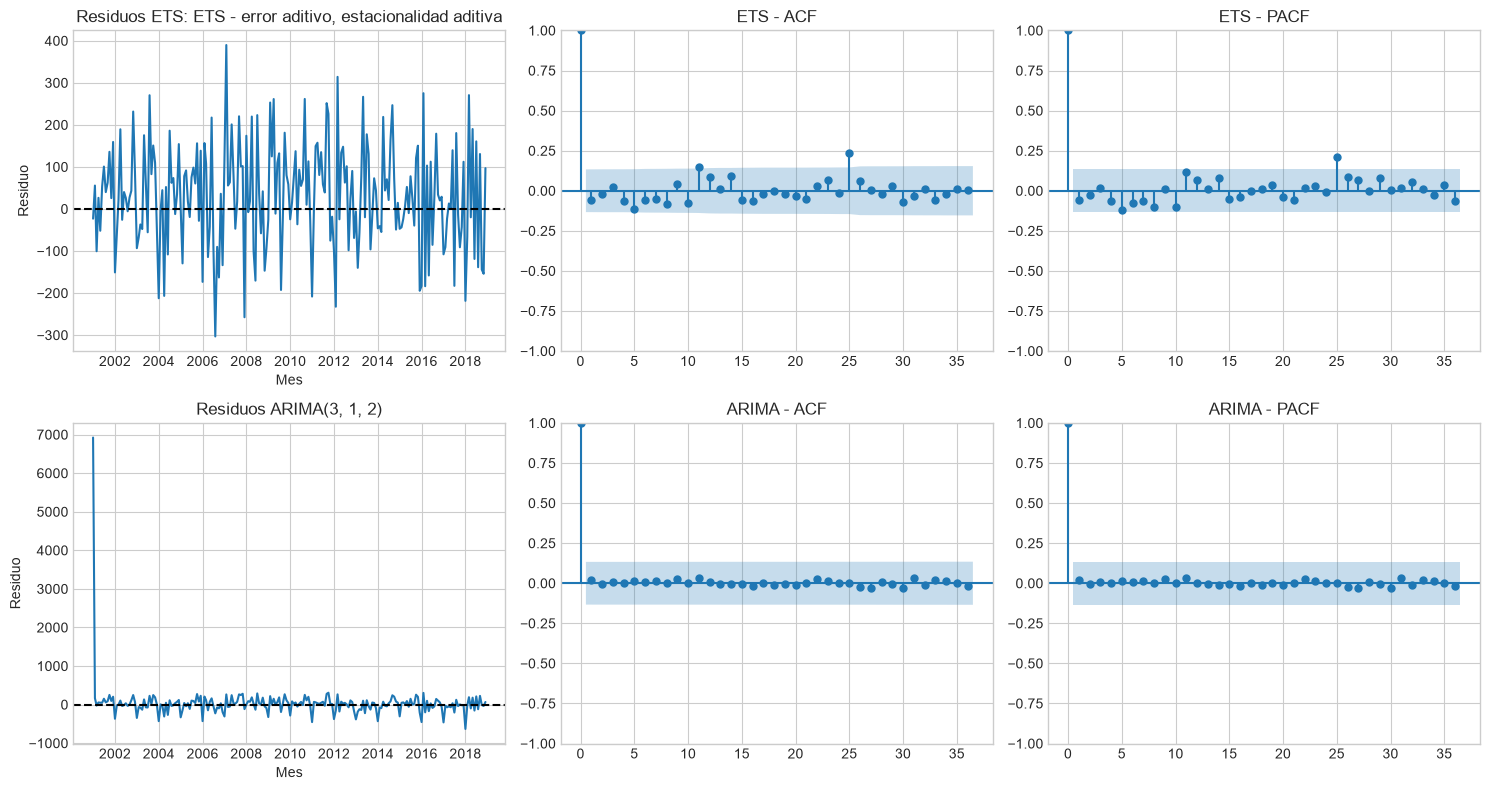

In [86]:
# --- Comparación única ETS ganador vs. mejor ARIMA ---
ets_scores = validation_scores[validation_scores["Modelo"].str.startswith("ETS")]
if ets_scores.empty:
    raise ValueError("No se encontraron modelos ETS en la comparación.")
ets_winner_name = ets_scores.iloc[0]["Modelo"]

arima_winner_fit, arima_winner_order = fit_arima_model(train_eval)
ets_winner_fit = fit_ets_model(ets_winner_name, train_eval)

ets_residuals = pd.Series(np.asarray(ets_winner_fit.resid, dtype=float), index=train_eval.index).dropna()
arima_residuals_compare = pd.Series(np.asarray(arima_winner_fit.resid, dtype=float), index=train_eval.index).dropna()

print(f"ETS candidato ganador: {ets_winner_name}")
print(f"Mejor ARIMA por AIC: ARIMA{arima_winner_order}")

max_diagnostic_lags = min(20, max(1, len(train_eval) // 4))

def normality_pvalues(residual_values):
    jb_result = jarque_bera(residual_values)
    if hasattr(jb_result, "statistic"):
        jb_p = float(jb_result.pvalue)
    else:
        jb_p = float(jb_result[1])
    sw_p = float(shapiro(residual_values).pvalue)
    return jb_p, sw_p

def residual_diagnostic_summary(model_name, residual_values):
    residual_values = pd.Series(residual_values).dropna()

    ljung_lags = list(range(1, max_diagnostic_lags + 1))
    ljung = acorr_ljungbox(residual_values, lags=ljung_lags, return_df=True, boxpierce=True)
    ljung_squared = acorr_ljungbox(residual_values ** 2, lags=ljung_lags, return_df=True)

    arch_lags = min(12, max(1, len(residual_values) // 5))
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=FutureWarning)
        arch_test = het_arch(residual_values, nlags=arch_lags)

    lb_p = float(ljung["lb_pvalue"].iloc[-1])
    bp_p = float(ljung["bp_pvalue"].iloc[-1])
    lb_squared_p = float(ljung_squared["lb_pvalue"].iloc[-1])
    arch_p = float(arch_test[1])
    jb_p, sw_p = normality_pvalues(residual_values)

    signs = np.where(residual_values.to_numpy() > 0, 1, -1)
    n = len(signs)
    n_pos = int(np.sum(signs == 1))
    n_neg = n - n_pos
    runs = 1 + int(np.sum(signs[1:] != signs[:-1]))
    if n_pos == 0 or n_neg == 0:
        runs_p = 1.0
    else:
        expected_runs = (2 * n_pos * n_neg / n) + 1
        variance_runs = (
            2 * n_pos * n_neg * (2 * n_pos * n_neg - n)
            / (n * n * (n - 1))
        )
        runs_p = (
            1.0 if variance_runs <= 0
            else 2 * norm.sf(abs((runs - expected_runs) / np.sqrt(variance_runs)))
        )

    rmse_row = validation_scores.loc[validation_scores["Modelo"] == model_name]
    rmse_validation = (
        float(rmse_row["RMSE promedio (miles)"].iloc[0])
        if model_name != "ARIMA (búsqueda por AIC)"
        else float(validation_scores.loc[
            validation_scores["Modelo"] == "ARIMA (búsqueda por AIC)",
            "RMSE promedio (miles)",
        ].iloc[0])
    )

    return {
        "Modelo": model_name,
        "RMSE validación (miles)": rmse_validation,
        "Ljung-Box, rezago máximo": lb_p,
        "Box-Pierce, rezago máximo": bp_p,
        "Rachas": runs_p,
        "ARCH-LM": arch_p,
        "Ljung-Box e², rezago máximo": lb_squared_p,
        "Jarque-Bera": jb_p,
        "Shapiro-Wilk": sw_p,
        "Autocorrelación": "Pasa" if min(lb_p, bp_p, runs_p) >= 0.05 else "Falla",
        "Homoscedasticidad": "Pasa" if min(lb_squared_p, arch_p) >= 0.05 else "Falla",
        "Normalidad": "Pasa" if min(jb_p, sw_p) >= 0.05 else "Falla",
    }

comparison_table = pd.DataFrame([
    residual_diagnostic_summary(ets_winner_name, ets_residuals),
    residual_diagnostic_summary("ARIMA (búsqueda por AIC)", arima_residuals_compare),
])
print("Comparación resumida de diagnósticos sobre datos de desarrollo")
display(comparison_table.round(6))

comparison_lags = min(36, max(1, len(train_eval) // 2))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].plot(ets_residuals.index, ets_residuals)
axes[0, 0].axhline(0, color="black", linestyle="--")
axes[0, 0].set(title=f"Residuos ETS: {ets_winner_name}", xlabel="Mes", ylabel="Residuo")
plot_acf(ets_residuals, lags=comparison_lags, ax=axes[0, 1])
axes[0, 1].set_title("ETS - ACF")
plot_pacf(ets_residuals, lags=comparison_lags, ax=axes[0, 2], method="ywm")
axes[0, 2].set_title("ETS - PACF")

axes[1, 0].plot(arima_residuals_compare.index, arima_residuals_compare)
axes[1, 0].axhline(0, color="black", linestyle="--")
axes[1, 0].set(title=f"Residuos ARIMA{arima_winner_order}", xlabel="Mes", ylabel="Residuo")
plot_acf(arima_residuals_compare, lags=comparison_lags, ax=axes[1, 1])
axes[1, 1].set_title("ARIMA - ACF")
plot_pacf(arima_residuals_compare, lags=comparison_lags, ax=axes[1, 2], method="ywm")
axes[1, 2].set_title("ARIMA - PACF")

plt.tight_layout()
plt.show()


### 7.1. Diagnóstico detallado del mejor ARIMA

Esta sección presenta las pruebas individuales del ARIMA seleccionado por AIC. Se mantiene separada de la comparación ETS–ARIMA para no repetir todas las tablas: aquí se revisan p-valores, raíces y gráficos específicos del modelo.

- **No autocorrelación:** Ljung-Box, Box-Pierce y rachas; ACF/PACF.
- **Homoscedasticidad:** Ljung-Box sobre $e_t^2$, ARCH-LM y gráficos de varianza.
- **Normalidad:** Jarque-Bera, Shapiro-Wilk y Q-Q normal.
- **Estructura:** módulos de raíces AR y MA fuera del círculo unitario.

Se usa $\alpha=0.05$.


Modelo ARIMA evaluado: ARIMA(3, 1, 2)
Rezago máximo Ljung-Box/Box-Pierce: 20


,Categoría,Prueba,H0,Estadístico,p-valor,Veredicto
0,No autocorrelación,Ljung-Box (rezago 20),No hay autocorrelación conjunta hasta el rezag...,0.826641,1.000000,Pasa
1,No autocorrelación,Box-Pierce (rezago 20),No hay autocorrelación conjunta hasta el rezag...,0.781773,1.000000,Pasa
2,No autocorrelación,Rachas,Los signos se distribuyen aleatoriamente,-0.655659,0.512043,Pasa
3,Homoscedasticidad,Ljung-Box e² (rezago 20),La varianza condicional no presenta autocorrel...,0.003356,1.000000,Pasa
4,Homoscedasticidad,ARCH-LM (12 rezagos),No existen efectos ARCH,30.492540,0.002353,Falla
5,Normalidad,Jarque-Bera,Los residuos son normales,252864.283297,0.000000,Falla
6,Normalidad,Shapiro-Wilk,Los residuos son normales,0.262253,0.000000,Falla
7,Estacionariedad,Raíces AR,Todas las raíces AR están fuera del círculo un...,1.008545,1.000000,Pasa
8,Invertibilidad,Raíces MA,Todas las raíces MA están fuera del círculo un...,1.005481,1.000000,Pasa


Resumen semaforizado


,Categoría,Veredicto
0,No autocorrelación,Pasa
1,Homoscedasticidad,Falla
2,Normalidad,Falla
3,Estacionariedad,Pasa
4,Invertibilidad,Pasa


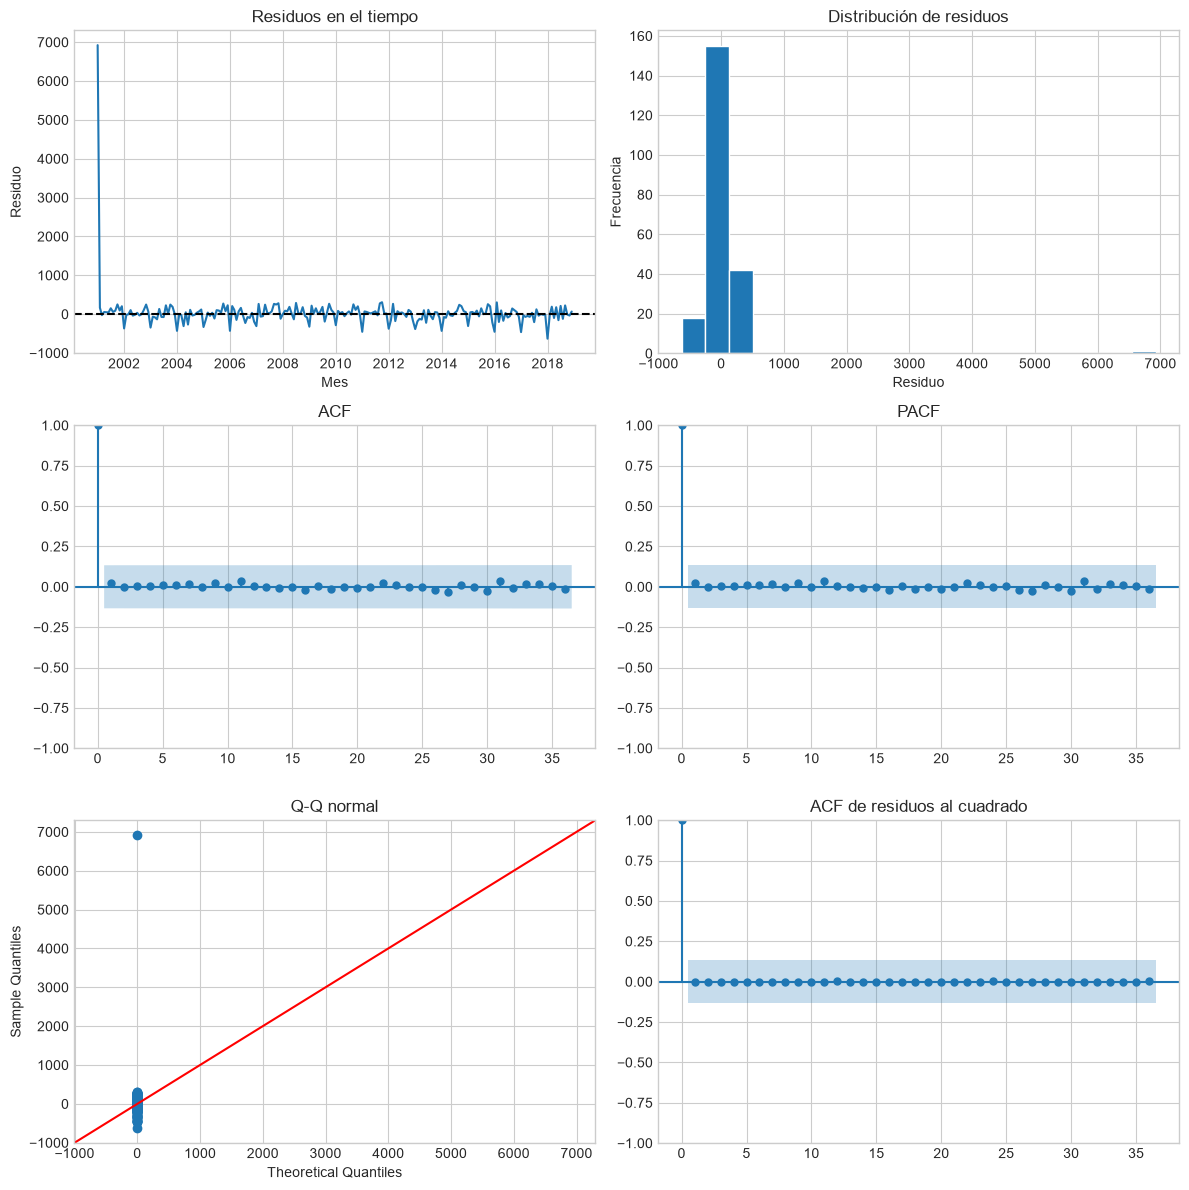

Módulo mínimo de raíces AR: 1.0085445443389565
Módulo mínimo de raíces MA: 1.005480695261589
ADVERTENCIA: normalidad rechazada; se deben usar intervalos bootstrap.


In [87]:
# --- Diagnóstico detallado único del mejor ARIMA ---
class ARIMADiagnostics:
    def __init__(self, fitted_result, residuals, alpha=0.05):
        self.fit = fitted_result
        self.residuals = pd.Series(np.asarray(residuals, dtype=float)).dropna()
        self.alpha = alpha
        self.max_lag = min(20, max(1, len(self.residuals) // 4))
        self.summary = []

    def _add(self, category, test, h0, statistic, pvalue):
        pvalue = float(pvalue)
        self.summary.append({
            "Categoría": category,
            "Prueba": test,
            "H0": h0,
            "Estadístico": float(statistic),
            "p-valor": pvalue,
            "Veredicto": "Pasa" if pvalue >= self.alpha else "Falla",
        })

    def check_autocorrelation(self):
        ljung_lags = list(range(1, self.max_lag + 1))
        ljung = acorr_ljungbox(self.residuals, lags=ljung_lags, return_df=True, boxpierce=True)
        lb_p = float(ljung["lb_pvalue"].iloc[-1])
        bp_p = float(ljung["bp_pvalue"].iloc[-1])
        self._add("No autocorrelación", f"Ljung-Box (rezago {self.max_lag})",
                  "No hay autocorrelación conjunta hasta el rezago máximo",
                  ljung["lb_stat"].iloc[-1], lb_p)
        self._add("No autocorrelación", f"Box-Pierce (rezago {self.max_lag})",
                  "No hay autocorrelación conjunta hasta el rezago máximo",
                  ljung["bp_stat"].iloc[-1], bp_p)

        signs = np.where(self.residuals.to_numpy() > 0, 1, -1)
        n = len(signs)
        n_pos = int(np.sum(signs == 1))
        n_neg = n - n_pos
        runs = 1 + int(np.sum(signs[1:] != signs[:-1]))
        if n_pos == 0 or n_neg == 0:
            runs_stat, runs_p = 0.0, 1.0
        else:
            expected = (2 * n_pos * n_neg / n) + 1
            variance = 2 * n_pos * n_neg * (2 * n_pos * n_neg - n) / (n * n * (n - 1))
            if variance <= 0:
                runs_stat, runs_p = 0.0, 1.0
            else:
                runs_stat = (runs - expected) / np.sqrt(variance)
                runs_p = 2 * norm.sf(abs(runs_stat))
        self._add("No autocorrelación", "Rachas",
                  "Los signos se distribuyen aleatoriamente", runs_stat, runs_p)
        return lb_p, bp_p, runs_p

    def check_heteroscedasticity(self):
        ljung_lags = list(range(1, self.max_lag + 1))
        lb_squared = acorr_ljungbox(self.residuals ** 2, lags=ljung_lags, return_df=True)
        lb_squared_p = float(lb_squared["lb_pvalue"].iloc[-1])
        arch_lags = min(12, max(1, len(self.residuals) // 5))
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=FutureWarning)
            arch_test = het_arch(self.residuals, nlags=arch_lags)
        arch_p = float(arch_test[1])
        self._add("Homoscedasticidad", f"Ljung-Box e² (rezago {self.max_lag})",
                  "La varianza condicional no presenta autocorrelación",
                  lb_squared["lb_stat"].iloc[-1], lb_squared_p)
        self._add("Homoscedasticidad", f"ARCH-LM ({arch_lags} rezagos)",
                  "No existen efectos ARCH", arch_test[0], arch_p)
        return lb_squared_p, arch_p

    def check_normality(self):
        jb_result = jarque_bera(self.residuals)
        if hasattr(jb_result, "statistic"):
            jb_stat, jb_p = float(jb_result.statistic), float(jb_result.pvalue)
        else:
            jb_stat, jb_p = float(jb_result[0]), float(jb_result[1])
        sw_result = shapiro(self.residuals)
        sw_stat, sw_p = float(sw_result.statistic), float(sw_result.pvalue)
        self._add("Normalidad", "Jarque-Bera", "Los residuos son normales", jb_stat, jb_p)
        self._add("Normalidad", "Shapiro-Wilk", "Los residuos son normales", sw_stat, sw_p)
        return jb_p, sw_p

    def check_roots(self):
        ar_roots = np.asarray(getattr(self.fit, "arroots", []), dtype=complex)
        ma_roots = np.asarray(getattr(self.fit, "maroots", []), dtype=complex)
        ar_ok = len(ar_roots) == 0 or np.all(np.abs(ar_roots) > 1)
        ma_ok = len(ma_roots) == 0 or np.all(np.abs(ma_roots) > 1)
        ar_min = np.nan if len(ar_roots) == 0 else float(np.min(np.abs(ar_roots)))
        ma_min = np.nan if len(ma_roots) == 0 else float(np.min(np.abs(ma_roots)))
        self._add("Estacionariedad", "Raíces AR", "Todas las raíces AR están fuera del círculo unitario",
                  ar_min, 1.0 if ar_ok else 0.0)
        self._add("Invertibilidad", "Raíces MA", "Todas las raíces MA están fuera del círculo unitario",
                  ma_min, 1.0 if ma_ok else 0.0)
        return ar_roots, ma_roots

    def run_full_diagnostics(self):
        lb_p, bp_p, runs_p = self.check_autocorrelation()
        lb_squared_p, arch_p = self.check_heteroscedasticity()
        jb_p, sw_p = self.check_normality()
        ar_roots, ma_roots = self.check_roots()
        return pd.DataFrame(self.summary), (lb_p, bp_p, runs_p), (lb_squared_p, arch_p), (jb_p, sw_p), ar_roots, ma_roots

arima_diagnostic_fit, arima_order = fit_arima_model(train_eval)
arima_residuals = pd.Series(np.asarray(arima_diagnostic_fit.resid, dtype=float), index=train_eval.index).dropna()
arima_diagnostics = ARIMADiagnostics(arima_diagnostic_fit, arima_residuals, alpha=0.05)
(
    arima_diagnostics_table,
    arima_autocorrelation,
    arima_heteroscedasticity,
    arima_normality,
    arima_ar_roots,
    arima_ma_roots,
) = arima_diagnostics.run_full_diagnostics()

print(f"Modelo ARIMA evaluado: ARIMA{arima_order}")
print(f"Rezago máximo Ljung-Box/Box-Pierce: {arima_diagnostics.max_lag}")
display(arima_diagnostics_table.round(6))

lb_p, bp_p, runs_p = arima_autocorrelation
lb_squared_p, arch_p = arima_heteroscedasticity
jb_p, sw_p = arima_normality
autocorrelation_ok = min(lb_p, bp_p, runs_p) >= 0.05
homoscedasticity_ok = min(lb_squared_p, arch_p) >= 0.05
normality_ok = min(jb_p, sw_p) >= 0.05
ar_roots_ok = len(arima_ar_roots) == 0 or np.all(np.abs(arima_ar_roots) > 1)
ma_roots_ok = len(arima_ma_roots) == 0 or np.all(np.abs(arima_ma_roots) > 1)

arima_category_summary = pd.DataFrame([
    {"Categoría": "No autocorrelación", "Veredicto": "Pasa" if autocorrelation_ok else "Falla"},
    {"Categoría": "Homoscedasticidad", "Veredicto": "Pasa" if homoscedasticity_ok else "Falla"},
    {"Categoría": "Normalidad", "Veredicto": "Pasa" if normality_ok else "Falla"},
    {"Categoría": "Estacionariedad", "Veredicto": "Pasa" if ar_roots_ok else "Falla"},
    {"Categoría": "Invertibilidad", "Veredicto": "Pasa" if ma_roots_ok else "Falla"},
])
print("Resumen semaforizado")
display(arima_category_summary)

plot_lags = min(36, max(1, len(arima_residuals) // 2))
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes[0, 0].plot(arima_residuals.index, arima_residuals)
axes[0, 0].axhline(0, color="black", linestyle="--")
axes[0, 0].set(title="Residuos en el tiempo", xlabel="Mes", ylabel="Residuo")
axes[0, 1].hist(arima_residuals, bins=20, edgecolor="white")
axes[0, 1].set(title="Distribución de residuos", xlabel="Residuo", ylabel="Frecuencia")
plot_acf(arima_residuals, lags=plot_lags, ax=axes[1, 0])
axes[1, 0].set_title("ACF")
plot_pacf(arima_residuals, lags=plot_lags, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF")
sm.qqplot(arima_residuals, line="45", ax=axes[2, 0])
axes[2, 0].set_title("Q-Q normal")
plot_acf(arima_residuals ** 2, lags=plot_lags, ax=axes[2, 1])
axes[2, 1].set_title("ACF de residuos al cuadrado")
plt.tight_layout()
plt.show()

print("Módulo mínimo de raíces AR:", np.nan if len(arima_ar_roots) == 0 else float(np.min(np.abs(arima_ar_roots))))
print("Módulo mínimo de raíces MA:", np.nan if len(arima_ma_roots) == 0 else float(np.min(np.abs(arima_ma_roots))))

if not normality_ok:
    print("ADVERTENCIA: normalidad rechazada; se deben usar intervalos bootstrap.")
    arima_bootstrap_intervals = True
else:
    arima_bootstrap_intervals = False


## 8. Pronóstico de seis meses

El modelo ganador se reajusta con toda la serie disponible y pronostica los seis meses posteriores a la última observación. Se reportan los valores puntuales con **intervalos de predicción del 95 %**. ETS usa `get_prediction` y `pred_int`. Si ARIMA es el ganador, el cuaderno usa intervalos analíticos de `get_forecast(conf_int)` cuando no se rechaza la normalidad de los residuos; si Jarque-Bera o Shapiro-Wilk rechazan la normalidad, usa 5.000 remuestreos de los residuos históricos para construir intervalos bootstrap. El intervalo se amplía con el horizonte y es la lectura recomendada del pronóstico. El resultado depende de la fecha de corte y de los datos del Excel.


Modelo ETS - error aditivo, estacionalidad aditiva reajustado con toda la serie. Parámetros de suavización: α (alfa)=0.592, β (beta)=No aplica, γ (gamma)=0.000


,Point_forecast,lower_95,upper_95,"Pronóstico (personas, aprox.)"
2019-07-01,10879.172,10650.270,11108.073,10879172
2019-08-01,10853.572,10587.559,11119.585,10853572
2019-09-01,10913.087,10614.540,11211.634,10913087
2019-10-01,11023.293,10695.426,11351.161,11023293
2019-11-01,11033.282,10678.509,11388.056,11033282
2019-12-01,10939.519,10559.741,11319.298,10939519


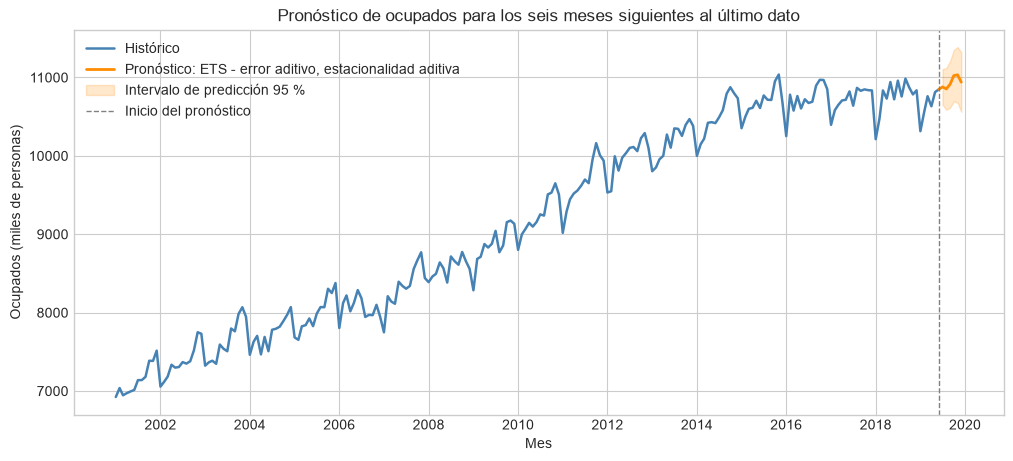

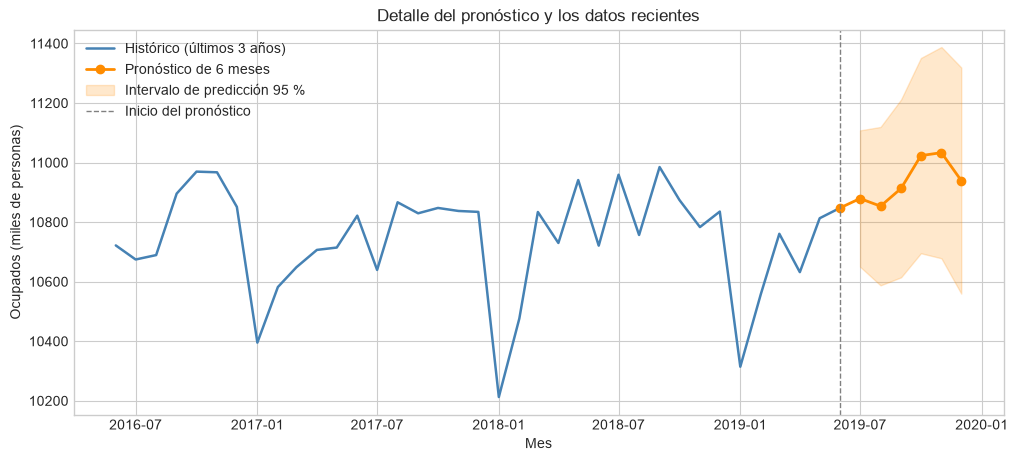

Último dato observado: 2019-06 = 10,848.000 miles de personas
Horizonte pronosticado: 2019-07 a 2019-12
Mejor configuración seleccionada en validación: ETS - error aditivo, estacionalidad aditiva
Ancho del intervalo del 95 %: 458 miles en el primer mes y 760 miles en el sexto.


In [88]:
# --- Pronóstico final: reajuste con toda la serie e intervalos de predicción del 95 % ---
if best_model_name == "ARIMA (búsqueda por AIC)":
    final_fit, final_order = fit_arima_model(y)
else:
    final_fit = fit_ets_model(best_model_name, y)
if best_model_name == "ARIMA (búsqueda por AIC)":
    arima_prediction = final_fit.get_forecast(steps=HORIZON)
    final_forecast_values = np.asarray(arima_prediction.predicted_mean, dtype=float)
else:
    final_forecast_values = np.asarray(final_fit.forecast(HORIZON), dtype=float)
future_index = pd.date_range(start=y.index[-1], periods=HORIZON + 1, freq="MS")[1:]

# Intervalos con el mismo procedimiento visto en clase: get_prediction + pred_int
if best_model_name == "ARIMA (búsqueda por AIC)":
    arima_prediction = final_fit.get_forecast(steps=HORIZON)
    point_forecasts = arima_prediction.predicted_mean.to_numpy(dtype=float)

    if arima_bootstrap_intervals:
        np.random.seed(123)
        bootstrap_residuals = np.asarray(arima_diagnostic_fit.resid, dtype=float)
        bootstrap_residuals = bootstrap_residuals[np.isfinite(bootstrap_residuals)]
        n_bootstrap = 5000
        simulated = np.empty((n_bootstrap, HORIZON), dtype=float)
        for horizon_step in range(HORIZON):
            sampled = np.random.choice(
                bootstrap_residuals,
                size=n_bootstrap,
                replace=True,
            )
            simulated[:, horizon_step] = point_forecasts[horizon_step] + sampled

        lower = np.quantile(simulated, 0.025, axis=0)
        upper = np.quantile(simulated, 0.975, axis=0)
        print("Intervalos ARIMA bootstrap: normalidad rechazada; no se usan intervalos gaussianos.")
    else:
        arima_conf_int = arima_prediction.conf_int(alpha=0.05)
        lower = arima_conf_int.iloc[:, 0].to_numpy(dtype=float)
        upper = arima_conf_int.iloc[:, 1].to_numpy(dtype=float)
        print("Intervalos ARIMA analíticos: no se rechaza la normalidad de residuos.")

    preds_final = pd.DataFrame({
        "Point_forecast": point_forecasts,
        "lower_95": lower,
        "upper_95": upper,
    }, index=future_index)
else:
    ci = final_fit.get_prediction(start=future_index[0], end=future_index[-1])
    preds_final = pd.concat(
        [pd.Series(ci.predicted_mean, index=future_index), ci.pred_int(alpha=0.05).set_index(future_index)],
        axis=1,
    )
preds_final.columns = ["Point_forecast", "lower_95", "upper_95"]
if not np.isfinite(preds_final.to_numpy(dtype=float)).all():
    raise ValueError("Los intervalos de predicción contienen valores no finitos.")

forecast = preds_final["Point_forecast"].rename("Pronóstico de ocupados (miles)")
forecast_table = preds_final.copy()
forecast_table["Pronóstico (personas, aprox.)"] = np.rint(forecast_table["Point_forecast"] * 1000).astype("int64")

if best_model_name == "ARIMA (búsqueda por AIC)":
    print(f"Modelo ARIMA reajustado con toda la serie. Orden seleccionado por AIC: ARIMA{final_order}")
else:
    alpha_param = getattr(final_fit, "alpha", None)
    beta_param = getattr(final_fit, "beta", None)
    gamma_param = getattr(final_fit, "gamma", None)
    format_parameter = lambda value: f"{value:.3f}" if value is not None else "No aplica"
    print(
        f"Modelo {best_model_name} reajustado con toda la serie. Parámetros de suavización: "
        f"α (alfa)={format_parameter(alpha_param)}, "
        f"β (beta)={format_parameter(beta_param)}, "
        f"γ (gamma)={format_parameter(gamma_param)}"
    )
display(forecast_table.round(3))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y, label="Histórico", color="steelblue", linewidth=1.8)
forecast_line = pd.concat([y.iloc[-1:], forecast])
ax.plot(forecast_line.index, forecast_line, label=f"Pronóstico: {best_model_name}", color="darkorange", linewidth=2)
ax.fill_between(future_index, preds_final["lower_95"], preds_final["upper_95"],
                color="darkorange", alpha=0.2, label="Intervalo de predicción 95 %")
ax.axvline(y.index[-1], color="gray", linestyle="--", linewidth=1, label="Inicio del pronóstico")
ax.set(title="Pronóstico de ocupados para los seis meses siguientes al último dato", xlabel="Mes", ylabel="Ocupados (miles de personas)")
ax.legend()
plt.show()

recent_start = y.index[-1] - pd.DateOffset(years=3)
recent_history = y.loc[y.index >= recent_start]
recent_forecast_line = pd.concat([recent_history.iloc[-1:], forecast])
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(recent_history.index, recent_history, label="Histórico (últimos 3 años)", color="steelblue", linewidth=1.8)
ax.plot(recent_forecast_line.index, recent_forecast_line, label="Pronóstico de 6 meses", color="darkorange", marker="o", linewidth=2)
ax.fill_between(future_index, preds_final["lower_95"], preds_final["upper_95"],
                color="darkorange", alpha=0.2, label="Intervalo de predicción 95 %")
ax.axvline(y.index[-1], color="gray", linestyle="--", linewidth=1, label="Inicio del pronóstico")
ax.set(title="Detalle del pronóstico y los datos recientes", xlabel="Mes", ylabel="Ocupados (miles de personas)")
ax.legend()
plt.show()

print(f"Último dato observado: {y.index[-1]:%Y-%m} = {y.iloc[-1]:,.3f} miles de personas")
print(f"Horizonte pronosticado: {forecast.index[0]:%Y-%m} a {forecast.index[-1]:%Y-%m}")
print(f"Mejor configuración seleccionada en validación: {best_model_name}")
ancho_intervalo = preds_final["upper_95"] - preds_final["lower_95"]
print(f"Ancho del intervalo del 95 %: {ancho_intervalo.iloc[0]:.0f} miles en el primer mes y {ancho_intervalo.iloc[-1]:.0f} miles en el sexto.")


## 9. Conclusión y limitaciones

La selección se hace por RMSE promedio en seis bloques cronológicos de validación previos al período final. La prueba final de seis meses se reporta aparte para el modelo ya seleccionado, sin usarla para reajustar la elección. El desempeño del modelo ganador en prueba final se compara con su RMSE promedio de validación; si mejora o empeora ayuda a interpretar la estabilidad de la selección. La desviación estándar del RMSE y las métricas MAE y sMAPE ayudan a valorar la estabilidad y el tipo de error; aun así, seis bloques históricos no garantizan el mismo desempeño ante cambios estructurales futuros.

Los diagnósticos de residuos muestran que las regresiones de tendencia no cumplen los supuestos de Gauss-Markov (autocorrelación y varianza no constante), por lo que sus p-valores deben leerse con la salvedad de la sección 7; esta limitación es coherente con su desempeño predictivo frente a ETS y ARIMA. Los diagnósticos del modelo seleccionado por validación, sea ETS o ARIMA, se reportan también en la sección 7 y deben releerse al volver a ejecutar el cuaderno.

El pronóstico se entrega con intervalos de predicción del 95 %: los valores puntuales son el centro de un rango de incertidumbre que crece con el horizonte, y ese rango es la lectura recomendada. El pronóstico es una extrapolación estadística de la serie histórica, no una garantía. Los modelos incluidos no consideran variables externas (por ejemplo, cambios económicos o metodológicos en la fuente). Además, la fuente disponible llega solo hasta junio de 2019, así que las fechas pronosticadas son julio-diciembre de 2019. No debe interpretarse como una estimación actual sin actualizar los datos y volver a ejecutar todo el análisis.
